# Price Regression — Egyptian Real Estate Dataset

**Objective:** Train regression models to predict property prices in the Egyptian real estate market.  
Multiple algorithms are evaluated and compared; the best-performing model is saved for use in the Recommendation System stage.

**Input:** `../../data/processed/cleaned_all_egypt.csv`  
**Output:** `../../models/best_regression_model.joblib` · `../../models/regression_results.csv`



---
## 1. Load Required Libraries

In [1]:
# Standard data handling
import numpy as np
import pandas as pd

# Machine learning — preprocessing, pipelines, models, and evaluation
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Model persistence
import joblib
import os

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress minor warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

# Consistent plot styling
sns.set_theme(style='whitegrid', palette='tab10')
plt.rcParams['figure.dpi'] = 100

---
## 2. Load the Clean Dataset

In [2]:
# Load the preprocessed dataset — NOT the clustered file (would introduce data leakage)
dataset_path = '../../data/processed/cleaned_all_egypt.csv'
df = pd.read_csv(dataset_path)

print(f'Dataset shape: {df.shape}')

Dataset shape: (62977, 18)


In [3]:
# Preview the first five rows
df.head()

,id,title,price,currency,price_period,price_type,price_raw_value,property_type,location,latitude,longitude,images,share_url,bedrooms,bathrooms,size,amenities,category
0,52974566,Luxurious Living in the Heart of Hyde Park!,50000.0,EGP,monthly,rent_price,50000.0,Apartment,"Hyde Park, New Cairo City, Cairo",29.995922,31.554127,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,3.0,3.0,189.0,"['BA', 'SE', 'WC', 'LB']",rent
1,8653638,Apartment for Rent in Al Marasem Compound,35000.0,EGP,monthly,rent_price,35000.0,Apartment,"Moon Residences, Fifth Square, The 5th Settlem...",30.051462,31.538992,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,3.0,2.0,170.0,"['BA', 'BW', 'AC', 'BK', 'CP']",rent
2,52974180,Flat Ultra Super Lux First Use For Rent-Villette,70000.0,EGP,monthly,rent_price,70000.0,Apartment,"Villette, 5th Settlement Compounds, The 5th Se...",30.022596,31.545815,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,3.0,3.0,161.0,"['BA', 'AC', 'CP', 'BK', 'SE', 'WC', 'BL', 'LB']",rent
3,52969227,Studio for Rent — South Lotus (New Cairo),22000.0,EGP,monthly,rent_price,22000.0,Apartment,"South Lotus, El Lotus, New Cairo City, Cairo",30.019306,31.513653,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,1.0,1.0,80.0,"['BA', 'BW', 'AC', 'CP', 'BK', 'SP', 'SE', 'SY...",rent
4,52969105,Studio for Rent — Hyde Park New Cairo First Us,35000.0,EGP,monthly,rent_price,35000.0,Apartment,"Hyde Park, New Cairo City, Cairo",29.995922,31.554127,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,1.0,1.0,80.0,"['BA', 'BW', 'AC', 'CP', 'BK', 'CO', 'LB', 'BL...",rent


In [4]:
# Inspect column data types
df.dtypes

id                   int64
title                  str
price              float64
currency               str
price_period           str
price_type             str
price_raw_value    float64
property_type          str
location               str
latitude           float64
longitude          float64
images                 str
share_url              str
bedrooms           float64
bathrooms          float64
size               float64
amenities              str
category               str
dtype: object

---
## 3. Select Features for Regression

Only meaningful property attributes are selected as input features. The target variable is `price`.

**Included features:**
| Feature | Reason |
|---|---|
| `size` | Property area is one of the strongest price predictors |
| `bedrooms` | Distinguishes unit types and strongly correlates with price |
| `bathrooms` | Correlates with unit size and quality |
| `property_type` | Structurally different property kinds have different price ranges |
| `category` | Separates rent from sale — critical for pricing |
| `latitude` | Geographic location — north/south positioning affects price |
| `longitude` | Geographic location — east/west positioning affects price |

**Excluded columns and justification:**
- `id` — arbitrary identifier, carries no property information
- `title` — free-text, inconsistent, not suitable for regression
- `images` — URLs have no quantitative meaning
- `share_url` — URL identifier, irrelevant to property characteristics
- `currency`, `price_period`, `price_type`, `price_raw_value` — redundant with `price` and `category`; including them would cause leakage
- `location` — textual address replaced by `latitude`/`longitude`
- `amenities` — complex list format; not straightforward for regression without further engineering

In [5]:
# Define the feature set and target
numeric_features     = ['size', 'bedrooms', 'bathrooms', 'latitude', 'longitude']
categorical_features = ['property_type', 'category']
selected_features    = numeric_features + categorical_features
target               = 'price'

# Subset to features + target
df_model = df[selected_features + [target]].copy()

# Drop rows with any missing values in selected columns
df_model.dropna(inplace=True)
df_model.reset_index(drop=True, inplace=True)

print(f'Shape after selecting features and dropping nulls: {df_model.shape}')
df_model.head()

Shape after selecting features and dropping nulls: (52020, 8)


,size,bedrooms,bathrooms,latitude,longitude,property_type,category,price
0,189.0,3.0,3.0,29.995922,31.554127,Apartment,rent,50000.0
1,170.0,3.0,2.0,30.051462,31.538992,Apartment,rent,35000.0
2,161.0,3.0,3.0,30.022596,31.545815,Apartment,rent,70000.0
3,80.0,1.0,1.0,30.019306,31.513653,Apartment,rent,22000.0
4,80.0,1.0,1.0,29.995922,31.554127,Apartment,rent,35000.0


---
## 4. Target Variable Analysis

Before modelling, it is important to understand the distribution of the target variable `price`.  
Price data in real estate is typically heavily right-skewed; a log transformation often improves regression performance.

In [6]:
# Summary statistics of the raw price
print('Price summary statistics:')
print(df_model[target].describe())

Price summary statistics:
count    5.202000e+04
mean     7.858634e+06
std      2.249731e+07
min      1.000000e+03
25%      6.500000e+04
50%      2.820000e+05
75%      9.000000e+06
max      1.000000e+09
Name: price, dtype: float64


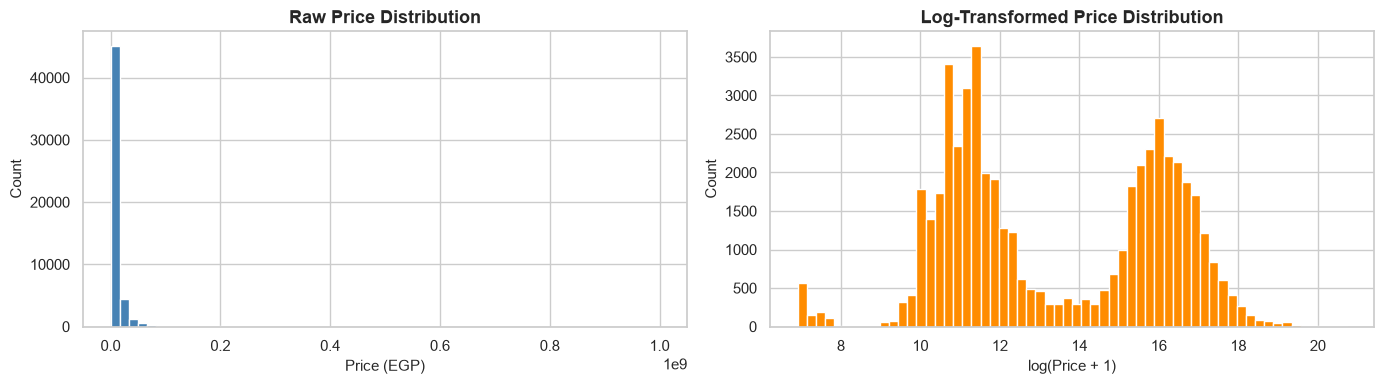


Using log-transformed price as the regression target for better model performance.


In [7]:
# Visualise the raw price distribution vs. log-transformed price
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Raw price
axes[0].hist(df_model[target], bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('Raw Price Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Price (EGP)', fontsize=11)
axes[0].set_ylabel('Count', fontsize=11)

# Log-transformed price
log_price = np.log1p(df_model[target])
axes[1].hist(log_price, bins=60, color='darkorange', edgecolor='white')
axes[1].set_title('Log-Transformed Price Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('log(Price + 1)', fontsize=11)
axes[1].set_ylabel('Count', fontsize=11)

plt.tight_layout()
plt.show()

print('\nUsing log-transformed price as the regression target for better model performance.')

---
## 5. Prepare Features and Target

The feature matrix `X` and the log-transformed target vector `y` are prepared.  
The dataset is then split into training (80%) and testing (20%) sets.

All preprocessing (scaling + encoding) is handled **inside a sklearn `Pipeline`** to prevent data leakage.

In [8]:
# Feature matrix and log-transformed target
X = df_model[selected_features]
y = np.log1p(df_model[target].values)

# Train / test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training set size : {X_train.shape[0]:,}')
print(f'Test set size     : {X_test.shape[0]:,}')

Training set size : 41,616
Test set size     : 10,404


---
## 6. Build the Preprocessing Pipeline

A `ColumnTransformer` applies the correct transformation to each column type:

| Column group | Transformer | Reason |
|---|---|---|
| Numeric | `StandardScaler` | Zero mean, unit variance — prevents magnitude dominance |
| Categorical | `OrdinalEncoder` | Maps string categories to integers inside the pipeline |

Wrapping these steps inside a `Pipeline` guarantees that the scaler and encoder are fit **only on the training fold**, making cross-validation and test-set evaluation fully leak-free.

In [9]:
# ColumnTransformer: scale numerics, encode categoricals
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features),
])

print('Preprocessor defined.')
print(f'  Numeric  features : {numeric_features}')
print(f'  Categorical features: {categorical_features}')

Preprocessor defined.
  Numeric  features : ['size', 'bedrooms', 'bathrooms', 'latitude', 'longitude']
  Categorical features: ['property_type', 'category']


---
## 7. Helper — Evaluate a Pipeline

A shared helper function trains a pipeline, predicts on the test set, and returns the three evaluation metrics.

In [10]:
def evaluate_pipeline(pipeline, X_train, y_train, X_test, y_test, name):
    """Fit pipeline on train set, evaluate on test set, return metrics dict."""
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)

    print(f'{name:<35} | MAE: {mae:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}')
    return {'Model': name, 'MAE': round(mae, 4), 'RMSE': round(rmse, 4), 'R²': round(r2, 4)}

# Master results list — populated section by section
all_results   = []
all_pipelines = {}  # name → fitted pipeline

---
## 8. Baseline — Dummy Regressor

Before any real model, a **baseline** is established using `DummyRegressor(strategy='mean')`.  
This model always predicts the mean of the training target, regardless of input features.

**Why is a baseline important?**  
A baseline sets the minimum acceptable performance bar. Any real regression model must surpass it to be considered useful. If a sophisticated model barely beats a mean predictor, it is a signal that the features carry little predictive power, or that data quality is poor.

In [11]:
# Dummy Regressor — always predicts the training mean
dummy_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor',    DummyRegressor(strategy='mean')),
])

result = evaluate_pipeline(dummy_pipeline, X_train, y_train, X_test, y_test, 'Dummy Regressor (mean)')
all_results.append(result)
all_pipelines['Dummy Regressor (mean)'] = dummy_pipeline

Dummy Regressor (mean)              | MAE: 2.5140 | RMSE: 2.7322 | R²: -0.0000


---
## 9. Linear Regression

Ordinary Least Squares fits a linear relationship between features and the log-transformed price.  
It is the simplest non-trivial model and provides interpretable coefficients.

In [12]:
# Linear Regression pipeline
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor',    LinearRegression()),
])

result = evaluate_pipeline(lr_pipeline, X_train, y_train, X_test, y_test, 'Linear Regression')
all_results.append(result)
all_pipelines['Linear Regression'] = lr_pipeline

Linear Regression                   | MAE: 0.8308 | RMSE: 1.2942 | R²: 0.7756


---
## 10. Polynomial Regression

Polynomial features expand the original feature set with interaction terms and higher-degree combinations, allowing a linear model to capture non-linear relationships.

Three degrees are compared:

| Degree | Description |
|---|---|
| 1 | Equivalent to plain Linear Regression |
| 2 | Adds squared terms and pairwise interactions |
| 3 | Adds cubic terms — higher expressive power but increased overfitting risk |

**Effect of increasing degree:**  
Higher degrees allow the model to fit the training data more closely, but they also increase the risk of **overfitting** — the model memorises noise and generalises poorly to unseen data. The gap between training R² and test R² widens as degree increases.

In [13]:
for degree in [1, 2, 3]:
    poly_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('poly',         PolynomialFeatures(degree=degree, include_bias=False)),
        ('regressor',    LinearRegression()),
    ])

    name   = f'Polynomial Regression (degree={degree})'
    result = evaluate_pipeline(poly_pipeline, X_train, y_train, X_test, y_test, name)
    all_results.append(result)
    all_pipelines[name] = poly_pipeline

Polynomial Regression (degree=1)    | MAE: 0.8308 | RMSE: 1.2942 | R²: 0.7756
Polynomial Regression (degree=2)    | MAE: 0.7683 | RMSE: 1.1874 | R²: 0.8111
Polynomial Regression (degree=3)    | MAE: 0.6145 | RMSE: 0.9672 | R²: 0.8747


---
## 11. Ridge Regression

Ridge adds an **L2 regularisation** term to the OLS loss, penalising large coefficients.  
This reduces overfitting and is particularly effective when features are correlated.

In [14]:
# Ridge Regression pipeline
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor',    Ridge(alpha=1.0)),
])

result = evaluate_pipeline(ridge_pipeline, X_train, y_train, X_test, y_test, 'Ridge Regression')
all_results.append(result)
all_pipelines['Ridge Regression'] = ridge_pipeline

Ridge Regression                    | MAE: 0.8308 | RMSE: 1.2942 | R²: 0.7756


---
## 12. Lasso Regression

Lasso adds an **L1 regularisation** term, which can shrink some coefficients exactly to zero.  
This provides automatic feature selection — irrelevant features are effectively removed.

In [15]:
# Lasso Regression pipeline
lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor',    Lasso(alpha=0.01)),
])

result = evaluate_pipeline(lasso_pipeline, X_train, y_train, X_test, y_test, 'Lasso Regression')
all_results.append(result)
all_pipelines['Lasso Regression'] = lasso_pipeline

Lasso Regression                    | MAE: 0.8318 | RMSE: 1.2946 | R²: 0.7755


---
## 13. ElasticNet Regression

ElasticNet combines **L1 and L2 regularisation**, blending the feature-selection ability of Lasso with the stability of Ridge.  
Two hyperparameters control its behaviour:

| Hyperparameter | Effect |
|---|---|
| `alpha` | Overall regularisation strength — higher values shrink coefficients more |
| `l1_ratio` | Mix between L1 and L2 — `0.0` = pure Ridge, `1.0` = pure Lasso |

The optimal combination is found via **5-fold cross-validation** on the training set, avoiding test-set leakage.

In [16]:
# Hyperparameter grid for ElasticNet
param_grid = {
    'regressor__alpha'    : [0.001, 0.01, 0.1, 1.0],
    'regressor__l1_ratio' : [0.1, 0.3, 0.5, 0.7, 0.9],
}

# Base ElasticNet pipeline
en_base_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor',    ElasticNet(max_iter=5000)),
])

# Grid search with 5-fold cross-validation
en_grid_search = GridSearchCV(
    en_base_pipeline,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=0,
)
en_grid_search.fit(X_train, y_train)

best_en_params = en_grid_search.best_params_
print(f'Best ElasticNet params (CV): {best_en_params}')
print(f'Best CV R²               : {en_grid_search.best_score_:.4f}')

Best ElasticNet params (CV): {'regressor__alpha': 0.01, 'regressor__l1_ratio': 0.9}
Best CV R²               : 0.7716


In [17]:
# Evaluate the best ElasticNet pipeline on the test set
en_best_pipeline = en_grid_search.best_estimator_

y_pred_en = en_best_pipeline.predict(X_test)
mae_en    = mean_absolute_error(y_test, y_pred_en)
rmse_en   = np.sqrt(mean_squared_error(y_test, y_pred_en))
r2_en     = r2_score(y_test, y_pred_en)

en_name = f'ElasticNet (alpha={best_en_params["regressor__alpha"]}, l1_ratio={best_en_params["regressor__l1_ratio"]})'
print(f'{en_name:<55} | MAE: {mae_en:.4f} | RMSE: {rmse_en:.4f} | R²: {r2_en:.4f}')

all_results.append({'Model': en_name, 'MAE': round(mae_en, 4), 'RMSE': round(rmse_en, 4), 'R²': round(r2_en, 4)})
all_pipelines[en_name] = en_best_pipeline

ElasticNet (alpha=0.01, l1_ratio=0.9)                   | MAE: 0.8316 | RMSE: 1.2946 | R²: 0.7755


---
## 14. Model Comparison

All linear regression models are ranked by **R²** on the held-out test set.

| Metric | Description |
|---|---|
| **MAE** | Mean Absolute Error — average absolute difference between predicted and actual log-price |
| **RMSE** | Root Mean Squared Error — penalises large errors more heavily than MAE |
| **R²** | Coefficient of determination — fraction of variance explained by the model (1.0 = perfect) |

All metrics are computed on the **held-out test set** to reflect real-world generalisation.

In [18]:
# Build and display the consolidated results table
results_df = (
    pd.DataFrame(all_results)
    .sort_values('R²', ascending=False)
    .reset_index(drop=True)
)

# Highlight the best row (index 0)
def highlight_best(row):
    return ['background-color: #d4edda; font-weight: bold'] * len(row) if row.name == 0 else [''] * len(row)

print('Results sorted by R² (best model highlighted):')
display(results_df.style.apply(highlight_best, axis=1))

Results sorted by R² (best model highlighted):


,Model,MAE,RMSE,R²
0,Polynomial Regression (degree=3),0.614500,0.967200,0.874700
1,Polynomial Regression (degree=2),0.768300,1.187400,0.811100
2,Polynomial Regression (degree=1),0.830800,1.294200,0.775600
3,Linear Regression,0.830800,1.294200,0.775600
4,Ridge Regression,0.830800,1.294200,0.775600
5,Lasso Regression,0.831800,1.294600,0.775500
6,"ElasticNet (alpha=0.01, l1_ratio=0.9)",0.831600,1.294600,0.775500
7,Dummy Regressor (mean),2.514000,2.732200,-0.000000


---
## 15. Model Comparison Visualisation

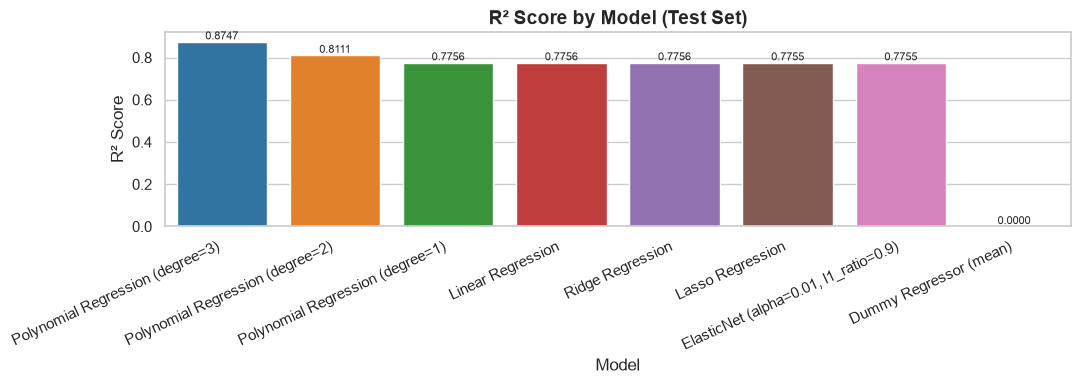

In [19]:
# --- Bar chart: R² scores across models ---
fig, ax = plt.subplots(figsize=(11, 4))

palette = sns.color_palette('tab10', n_colors=len(results_df))
sns.barplot(data=results_df, x='Model', y='R²', palette=palette, ax=ax)

ax.set_title('R² Score by Model (Test Set)', fontsize=14, fontweight='bold')
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('R² Score', fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right')

# Annotate each bar
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.4f}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

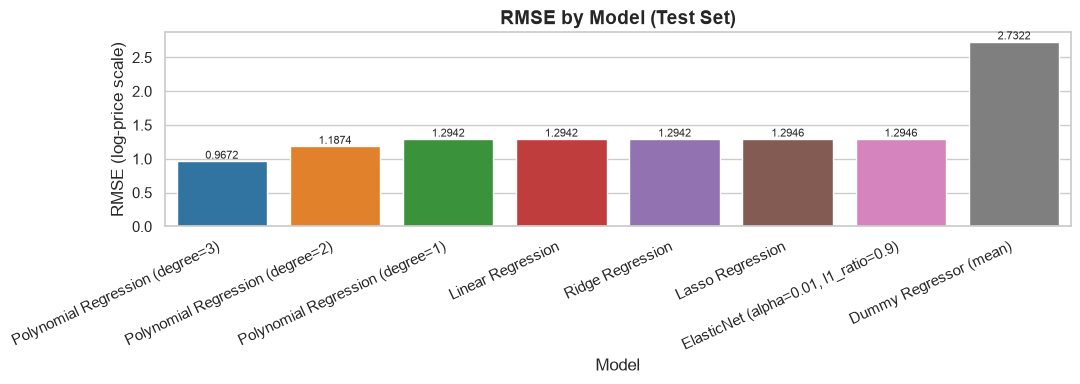

In [20]:
# --- Bar chart: RMSE scores across models ---
fig, ax = plt.subplots(figsize=(11, 4))

sns.barplot(data=results_df, x='Model', y='RMSE', palette=palette, ax=ax)

ax.set_title('RMSE by Model (Test Set)', fontsize=14, fontweight='bold')
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('RMSE (log-price scale)', fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.4f}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

---
## 16. Select the Best Model

The model with the highest **R²** score on the test set is selected as the best performer.

In [21]:
# Identify the best model by R²
best_model_name = results_df.iloc[0]['Model']
best_pipeline   = all_pipelines[best_model_name]

print(f'Best model: {best_model_name}')
print(f'  R²   : {results_df.iloc[0]["R²"]}')
print(f'  RMSE : {results_df.iloc[0]["RMSE"]}')
print(f'  MAE  : {results_df.iloc[0]["MAE"]}')

Best model: Polynomial Regression (degree=3)
  R²   : 0.8747
  RMSE : 0.9672
  MAE  : 0.6145


---
## 17. Residual Analysis

Residuals (actual − predicted) are examined to check model assumptions.  
A well-fitted model should have residuals that are centred near zero and roughly normally distributed.

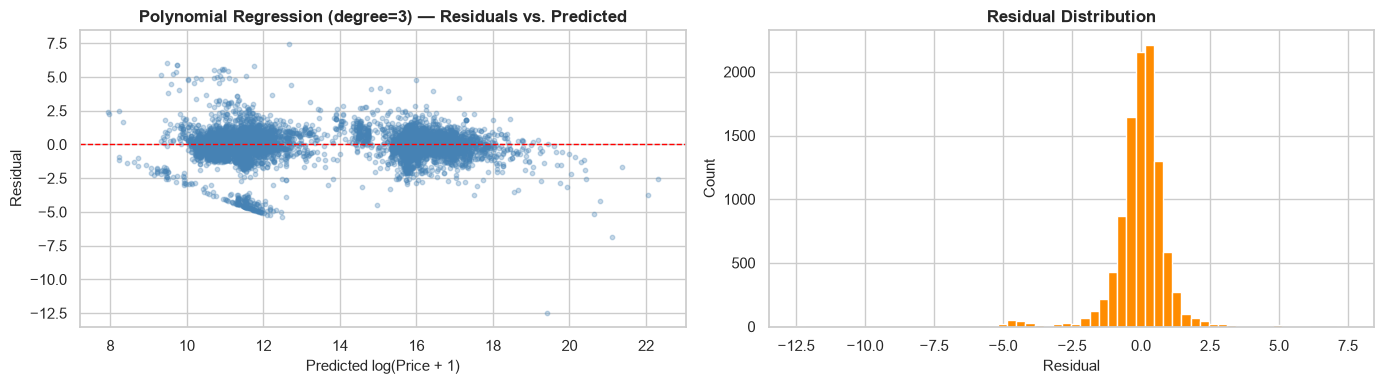

In [22]:
# Predictions and residuals for the best model
y_pred_best = best_pipeline.predict(X_test)
residuals   = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Residuals vs. Predicted
axes[0].scatter(y_pred_best, residuals, alpha=0.3, s=10, color='steelblue')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1)
axes[0].set_title(f'{best_model_name} — Residuals vs. Predicted', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted log(Price + 1)', fontsize=11)
axes[0].set_ylabel('Residual', fontsize=11)

# Residual distribution
axes[1].hist(residuals, bins=60, color='darkorange', edgecolor='white')
axes[1].set_title('Residual Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual', fontsize=11)
axes[1].set_ylabel('Count', fontsize=11)

plt.tight_layout()
plt.show()

---
## 18. Actual vs. Predicted Plot

A scatter plot of actual vs. predicted log-prices visualises how closely the model tracks real values.  
Points along the diagonal red line represent perfect predictions.

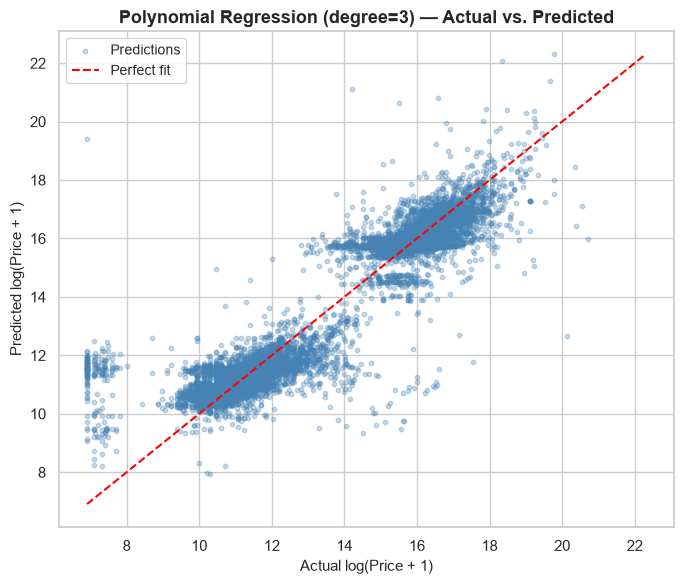

In [23]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(y_test, y_pred_best, alpha=0.3, s=10, color='steelblue', label='Predictions')

# Perfect-prediction line
min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Perfect fit')

ax.set_title(f'{best_model_name} — Actual vs. Predicted', fontsize=13, fontweight='bold')
ax.set_xlabel('Actual log(Price + 1)', fontsize=11)
ax.set_ylabel('Predicted log(Price + 1)', fontsize=11)
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

---
## 19. Feature Importance

For all linear models the absolute coefficient magnitudes are used as a proxy for feature importance.  
Larger absolute coefficients indicate features that have a stronger influence on the predicted log-price.

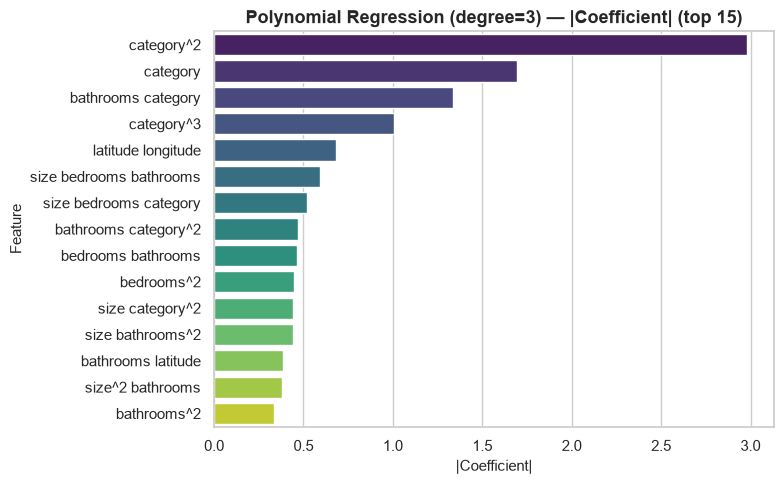

Top feature importances:


,Feature,Importance
0,category^2,2.982185
1,category,1.691699
2,bathrooms category,1.333584
3,category^3,1.006774
4,latitude longitude,0.680508
5,size bedrooms bathrooms,0.594491
6,size bedrooms category,0.518019
7,bathrooms category^2,0.471686
8,bedrooms bathrooms,0.465313
9,bedrooms^2,0.448004


In [24]:
# Extract the regressor step from the best pipeline
regressor_step = best_pipeline.named_steps.get('regressor')

if regressor_step is not None and hasattr(regressor_step, 'coef_'):
    coefs = regressor_step.coef_

    # For Polynomial pipelines the feature names expand — use indices if names mismatch
    poly_step = best_pipeline.named_steps.get('poly')
    if poly_step is not None:
        try:
            feature_names = poly_step.get_feature_names_out(selected_features)
        except Exception:
            feature_names = [f'x{i}' for i in range(len(coefs))]
    else:
        feature_names = selected_features

    importance_df = (
        pd.DataFrame({'Feature': feature_names, 'Importance': np.abs(coefs)})
        .sort_values('Importance', ascending=False)
        .head(15)   # show top-15 to keep plot readable
        .reset_index(drop=True)
    )

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis', ax=ax)
    ax.set_title(f'{best_model_name} — |Coefficient| (top 15)', fontsize=13, fontweight='bold')
    ax.set_xlabel('|Coefficient|', fontsize=11)
    ax.set_ylabel('Feature', fontsize=11)
    plt.tight_layout()
    plt.show()

    print('Top feature importances:')
    display(importance_df)
else:
    print('Feature importances not available for this model type (e.g. DummyRegressor).')

---
## 20. Save Results and Best Model

Two artifacts are written to `../../models/`:

| Artifact | Content |
|---|---|
| `regression_results.csv` | Full comparison table — all models, all metrics |
| `best_regression_model.joblib` | Fitted pipeline (preprocessor + best model) ready for inference |

In [25]:
# Ensure the models directory exists
models_dir = '../../models/regression'
os.makedirs(models_dir, exist_ok=True)

# --- Save results table ---
results_path = os.path.join(models_dir, 'regression_results.csv')
results_df.to_csv(results_path, index=False)
print(f'Results table saved to : {results_path}')

# --- Save best pipeline ---
model_path = os.path.join(models_dir, 'best_regression_model.joblib')
joblib.dump(best_pipeline, model_path)
print(f'Best model saved to    : {model_path}')
print(f'  Model     : {best_model_name}')
print(f'  Features  : {selected_features}')

Results table saved to : ../../models\regression_results.csv
Best model saved to    : ../../models\best_regression_model.joblib
  Model     : Polynomial Regression (degree=3)
  Features  : ['size', 'bedrooms', 'bathrooms', 'latitude', 'longitude', 'property_type', 'category']


---
## 21. Summary

| Step | Description |
|---|---|
| **Input** | `cleaned_all_egypt.csv` — 18 columns, ~63 K rows |
| **Features used** | `size`, `bedrooms`, `bathrooms`, `property_type`, `category`, `latitude`, `longitude` |
| **Target** | `log(price + 1)` — log-transformed for better model fit |
| **Preprocessing** | sklearn `Pipeline` + `ColumnTransformer` — scaling and encoding inside the pipeline |
| **Baseline** | `DummyRegressor(strategy='mean')` — establishes the minimum acceptable performance bar |
| **Models compared** | Dummy · Linear · Polynomial (deg 1/2/3) · Ridge · Lasso · ElasticNet (CV-tuned) |
| **Best model** | Selected by highest R² on the held-out test set |
| **Outputs** | `regression_results.csv` — full comparison table; `best_regression_model.joblib` — ready for inference |

**Next step →** `04_Recommendation` — Hybrid Recommendation System using cluster labels and predicted prices.